# Public data experiments
This is the notebook to run the public data experiment

In [1]:
import sys
from pathlib import Path

# Add the workspace root to sys.path
workspace_root = Path("/Users/eduardohome/workspace/benchmark_credit_scoring")
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

# Now you can import from src
from src.utils.csv_config import read_csv_by_name, create_imbalanced_datasets, merge_xai_results
from src.model.functions import save_model, load_model, get_split_data
from src.xai.functions import get_train_iterations_shap, compute_xai_metrics_from_shap
from src.graph.functions import plot_model_boxplot, plot_imbalance_boxplot_grid, load_xai_file, plot_models_by_imbalance

try:
    from src.model.functions import get_train_model
except Exception as exc:
    # provide helpful message if import fails
    print("Failed to import model utilities:", exc)
    print("This often means a missing dependency such as libomp for LightGBM.")
    print("On macOS you can install it with `brew install libomp` and then restart the kernel.")
    raise

# General imports
import pandas as pd
from pathlib import Path

In [2]:
# -------------------------
# Settings
# -------------------------
data_dir = Path("/Users/eduardohome/workspace/benchmark_credit_scoring/data")
#datasets_to_run = ["australian", "german", "japan", "kgccdea", "taiwan", "th02"] #kggmsc #taiwan
datasets_to_run = ["australian", "german", "japan", "kgccdea", "th02"] #kggmsc #taiwan
#datasets_to_run = ["australian"]
target_col = "target"

# Edit this list whenever you want more/less imbalance datasets
imbalance_levels = [10, 15, 20, 25, 30, 35, 40]
#imbalance_levels = [1, 2.5, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
n_iterations = 100
percentage = 90

# list of estimators understood by functions.get_model
model_choices = ["LightGBM", "XGBoost", "RandomForest", "BoostDT", "BoostSGB", "BagNN", "ANN"] #, "SVM-Rbf"
#model_choices = ["XGBoost"] #, "SVM-Rbf"
product = "default"

## Read data 

In [3]:
dataset = "german"

In [4]:
df_global = load_xai_file(
    data_dir=data_dir,
    dataset_name=dataset,
    file_type="all_models_resume_global",
)
df_global

,feature,rankstab_global,value_stab,feature_importance_global,value_stab_weight,rankstab_global_weight,dataset,imbalance,model
0,0,0.532828,0.423956,0.238072,10.093211,12.685163,german,10,XGBoost
1,1,0.581414,0.305827,0.255647,7.818365,14.863675,german,10,XGBoost
2,2,4.017273,2.130473,0.006776,1.443696,2.722269,german,10,XGBoost
3,3,1.599268,3.427165,0.002069,0.709186,0.330938,german,10,XGBoost
4,4,6.595960,0.958989,0.060885,5.838814,40.159583,german,10,XGBoost
...,...,...,...,...,...,...,...,...,...
1465,19,23.070303,0.274824,0.042995,1.181608,99.190910,german,50,ANN
1466,20,5.750606,0.211301,0.064009,1.352513,36.808910,german,50,ANN
1467,21,0.431818,0.487845,0.006932,0.338166,0.299329,german,50,ANN
1468,22,26.453636,0.334968,0.035845,1.200679,94.821861,german,50,ANN


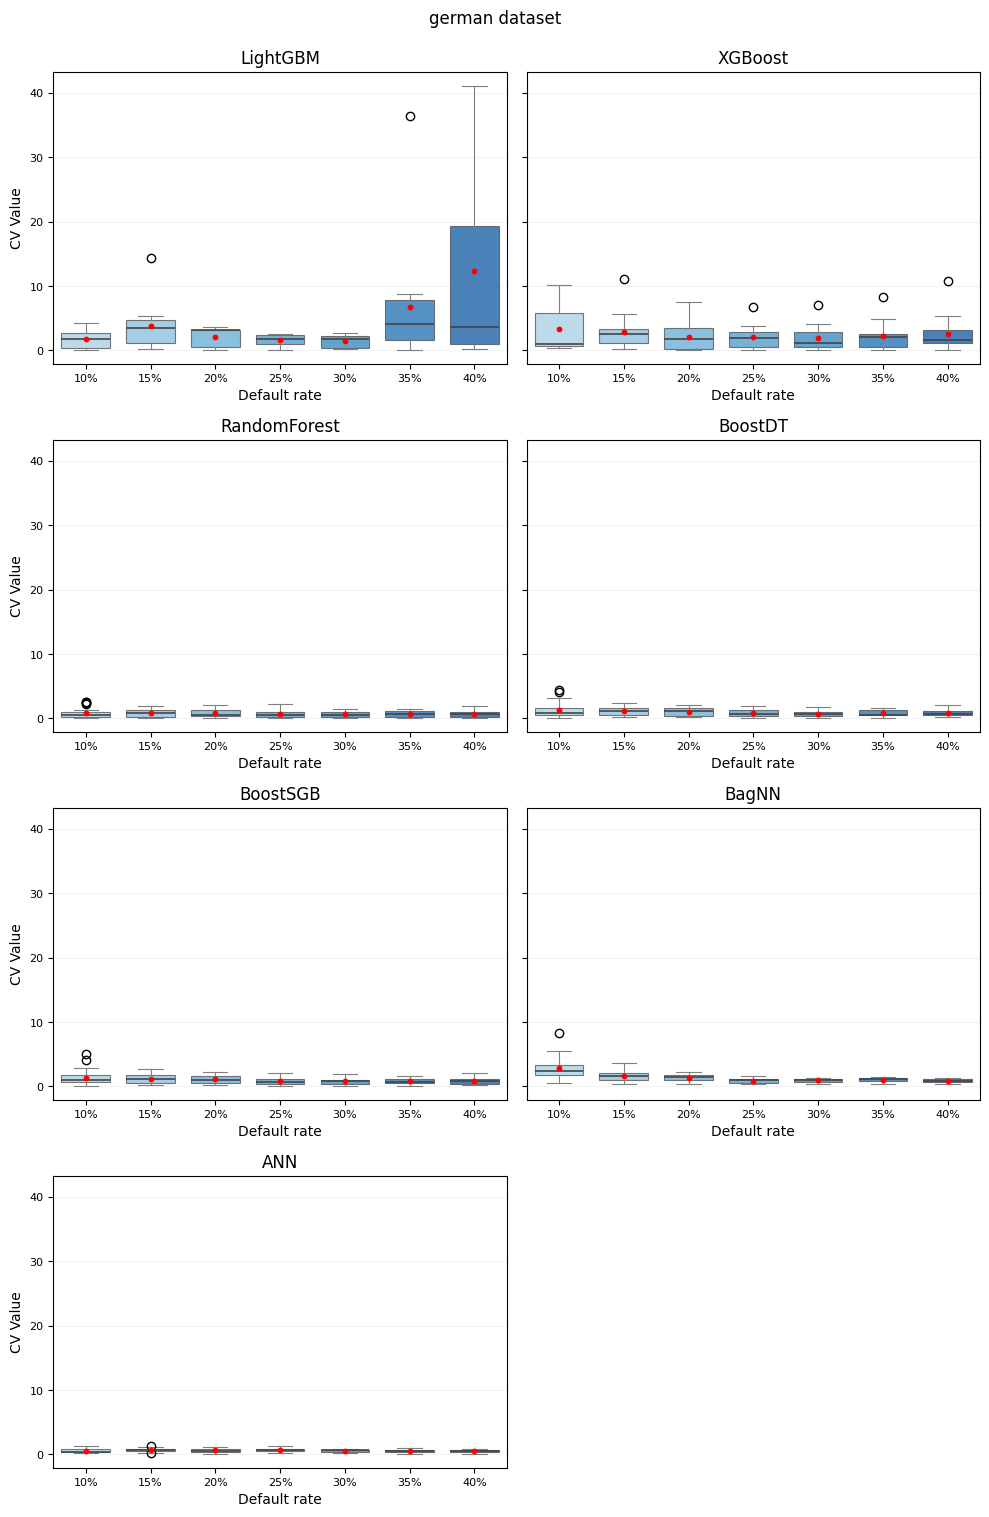

In [5]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_global,
    dataset=dataset,
    models=model_choices,
    metric="value_stab_weight",
    ylabel="CV Value",
    xlabel="Default rate",
    imbalance_order=imbalance_levels,
    ncols=2,
    suptitle=f"{dataset} dataset"
)

plt.show()


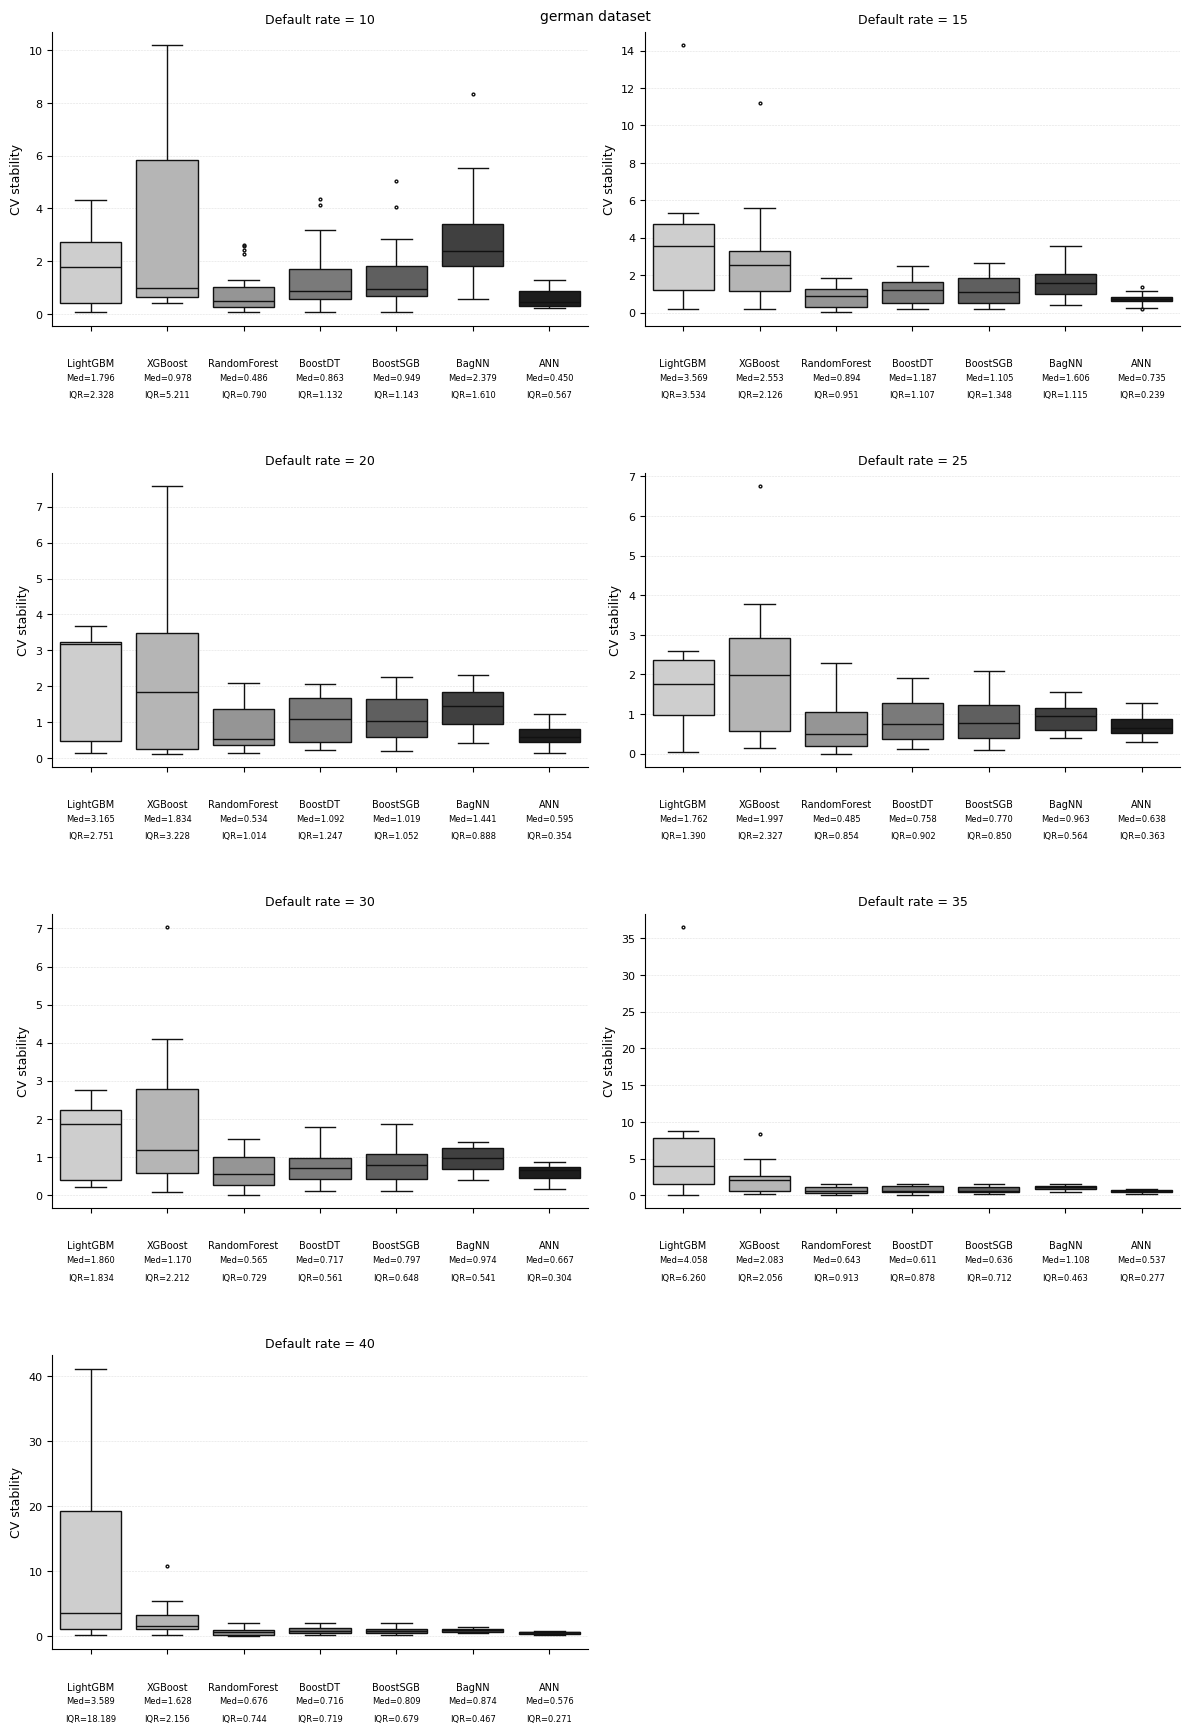

In [6]:
fig, axes = plot_models_by_imbalance(
    df=df_global,
    dataset=dataset,
    models=model_choices,
    imbalance_levels=imbalance_levels,
    metric="value_stab_weight",
    ylabel="CV stability",
    xlabel="Model",
    ncols=2,
    suptitle=f"{dataset} dataset",
)

plt.show()

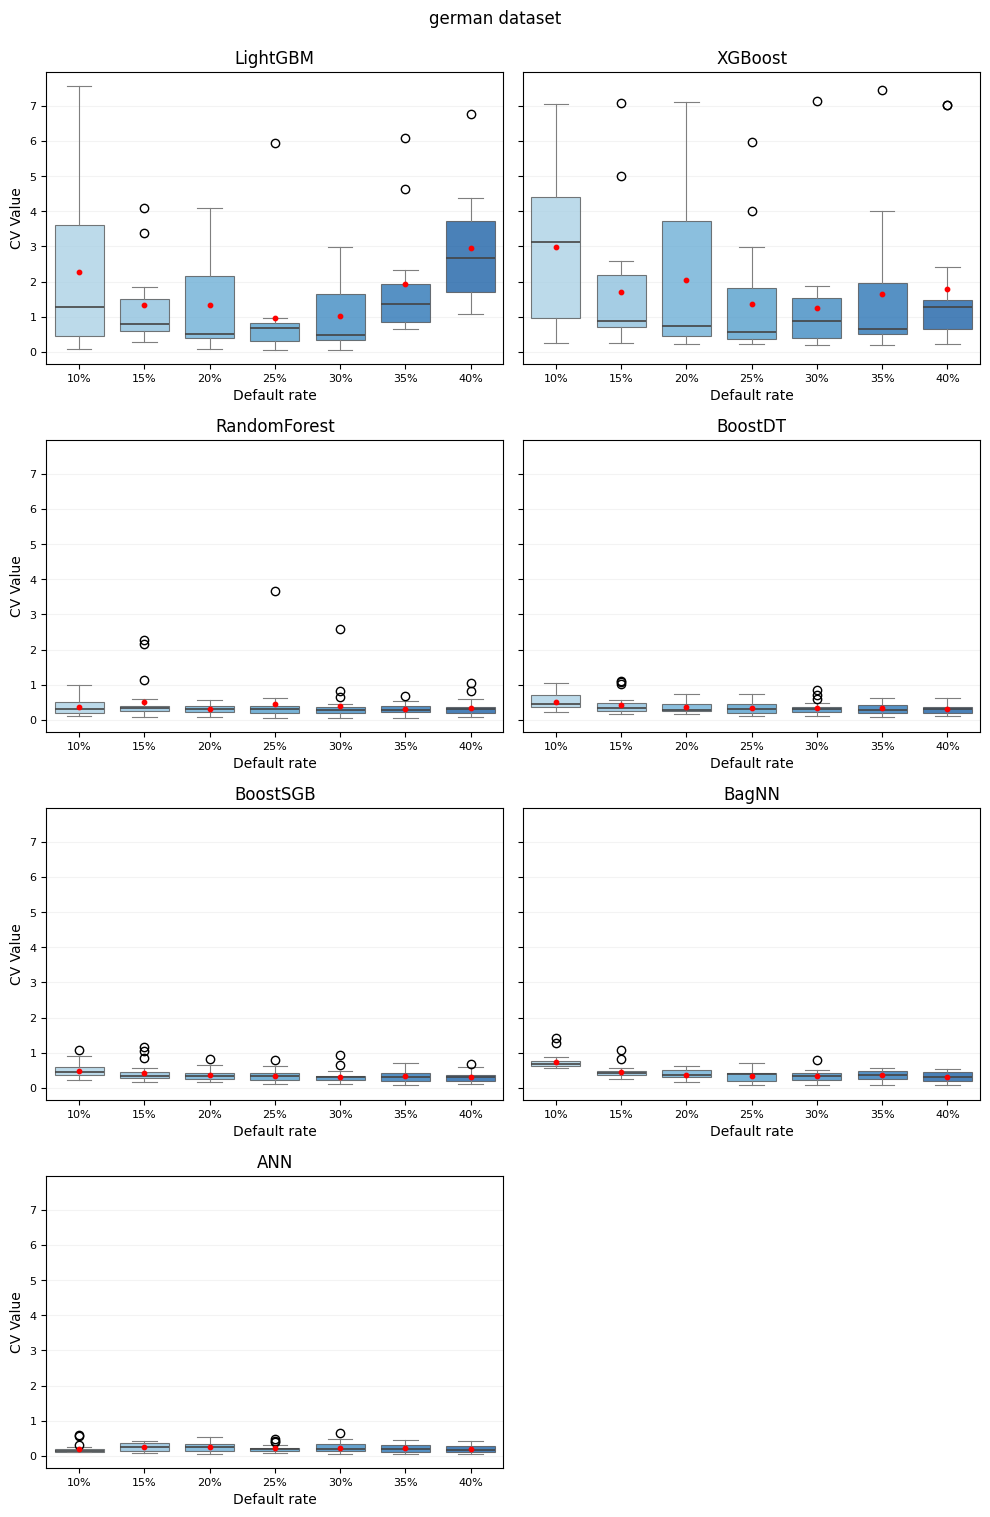

In [7]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_global,
    dataset=dataset,
    models=model_choices,
    metric="value_stab",
    ylabel="CV Value",
    xlabel="Default rate",
    imbalance_order=imbalance_levels,
    ncols=2,
    suptitle=f"{dataset} dataset"
)

plt.show()


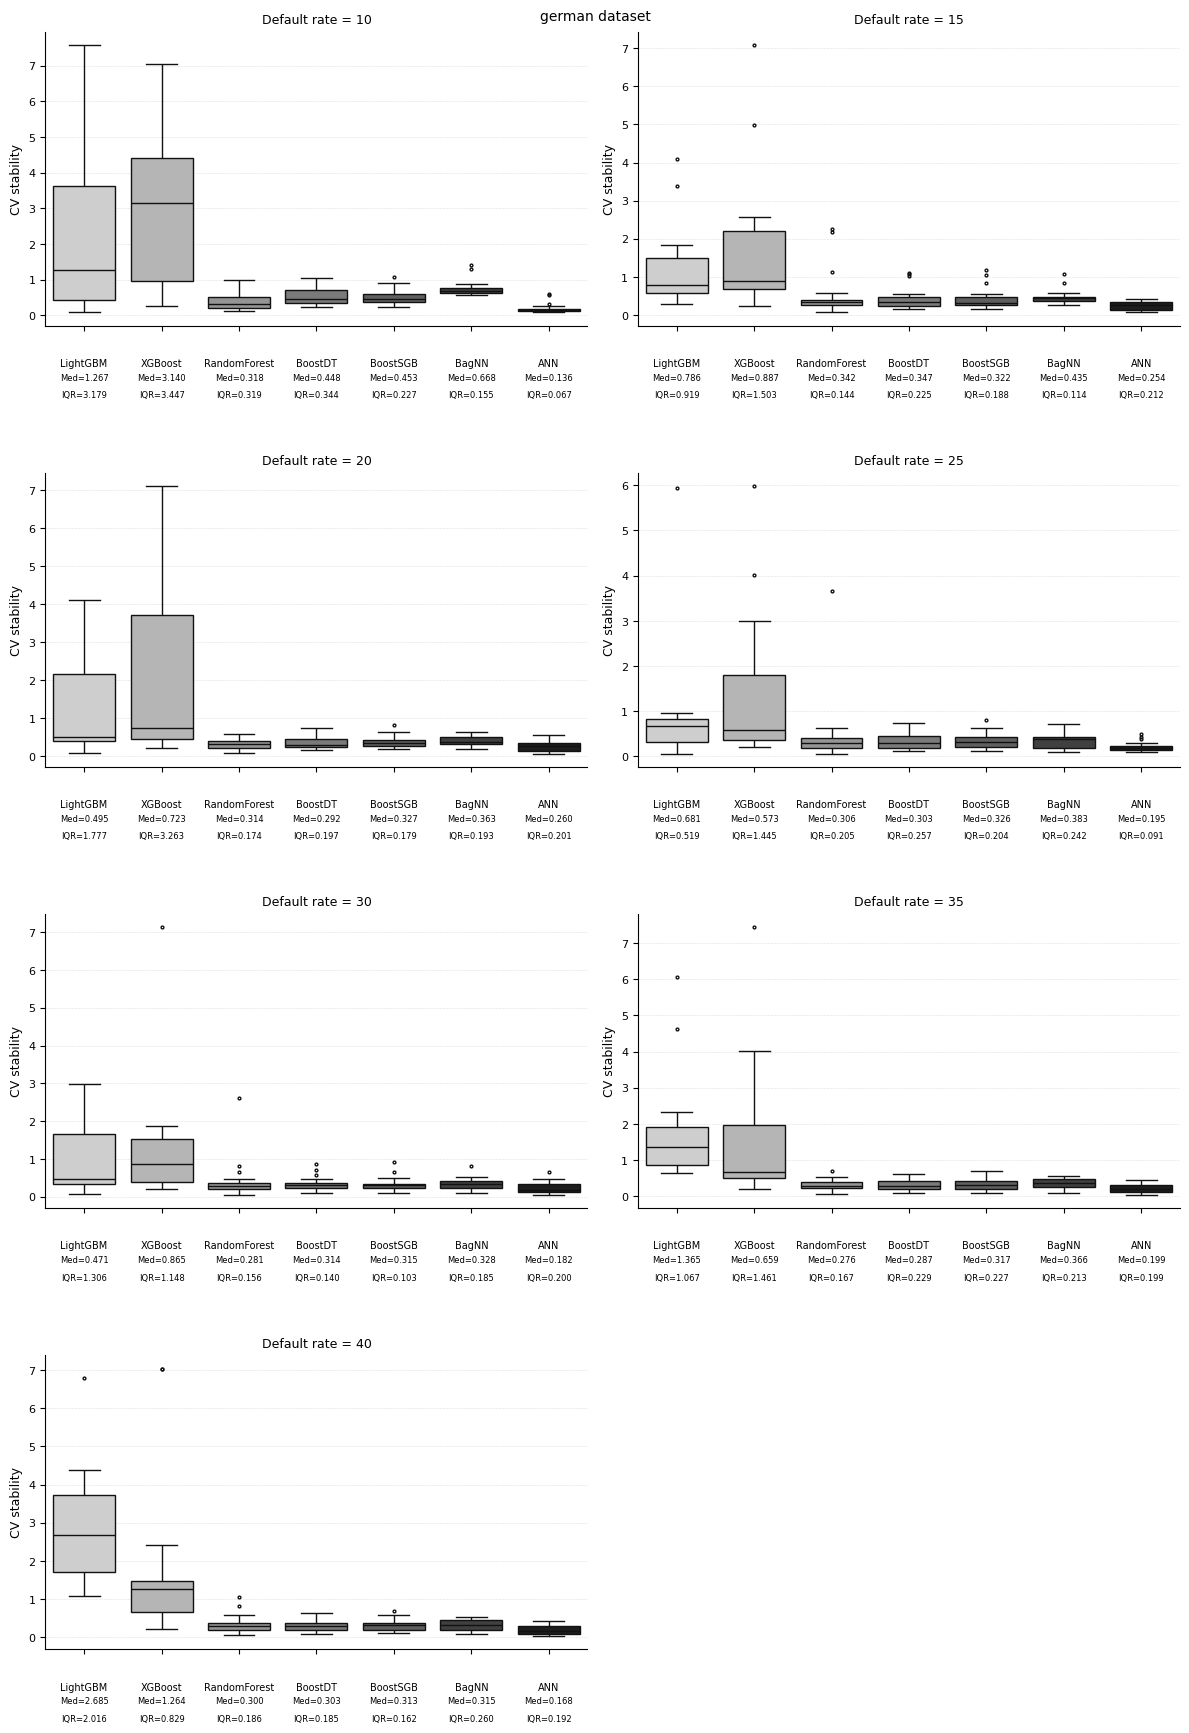

In [8]:
fig, axes = plot_models_by_imbalance(
    df=df_global,
    dataset=dataset,
    models=model_choices,
    imbalance_levels=imbalance_levels,
    metric="value_stab",
    ylabel="CV stability",
    xlabel="Model",
    ncols=2,
    suptitle=f"{dataset} dataset",
)

plt.show()

## Local Interpretability metrics

In [14]:
df_local = load_xai_file(
    data_dir=data_dir,
    dataset_name=dataset,
    file_type="all_models_resume_local",
)
df_local.head()

,index,rankstab_local,rankstab_local_weight,dataset,imbalance,model
0,1,0.468488,5.119119,german,10,XGBoost
1,2,0.466095,4.990226,german,10,XGBoost
2,3,0.445679,4.175809,german,10,XGBoost
3,4,0.439217,4.225748,german,10,XGBoost
4,6,0.442383,4.210777,german,10,XGBoost


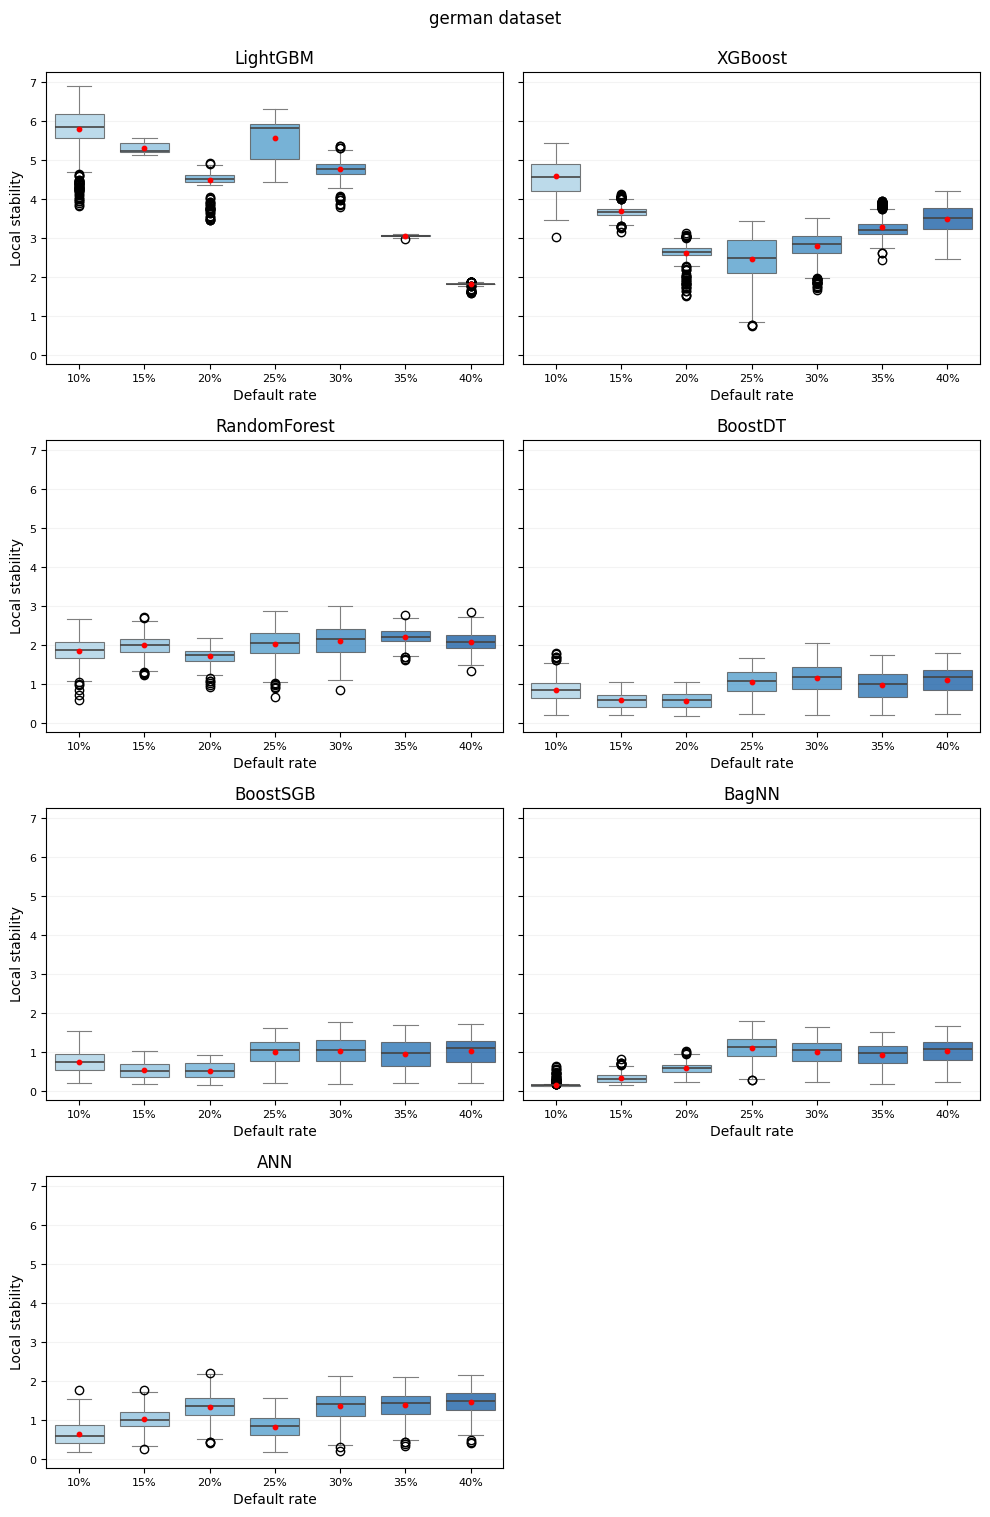

In [15]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_local,
    dataset=dataset,
    models=model_choices,
    metric="rankstab_local_weight",
    ylabel="Local stability",
    xlabel="Default rate",
    imbalance_order=imbalance_levels,
    ncols=2,
    suptitle=f"{dataset} dataset"
)

plt.show()


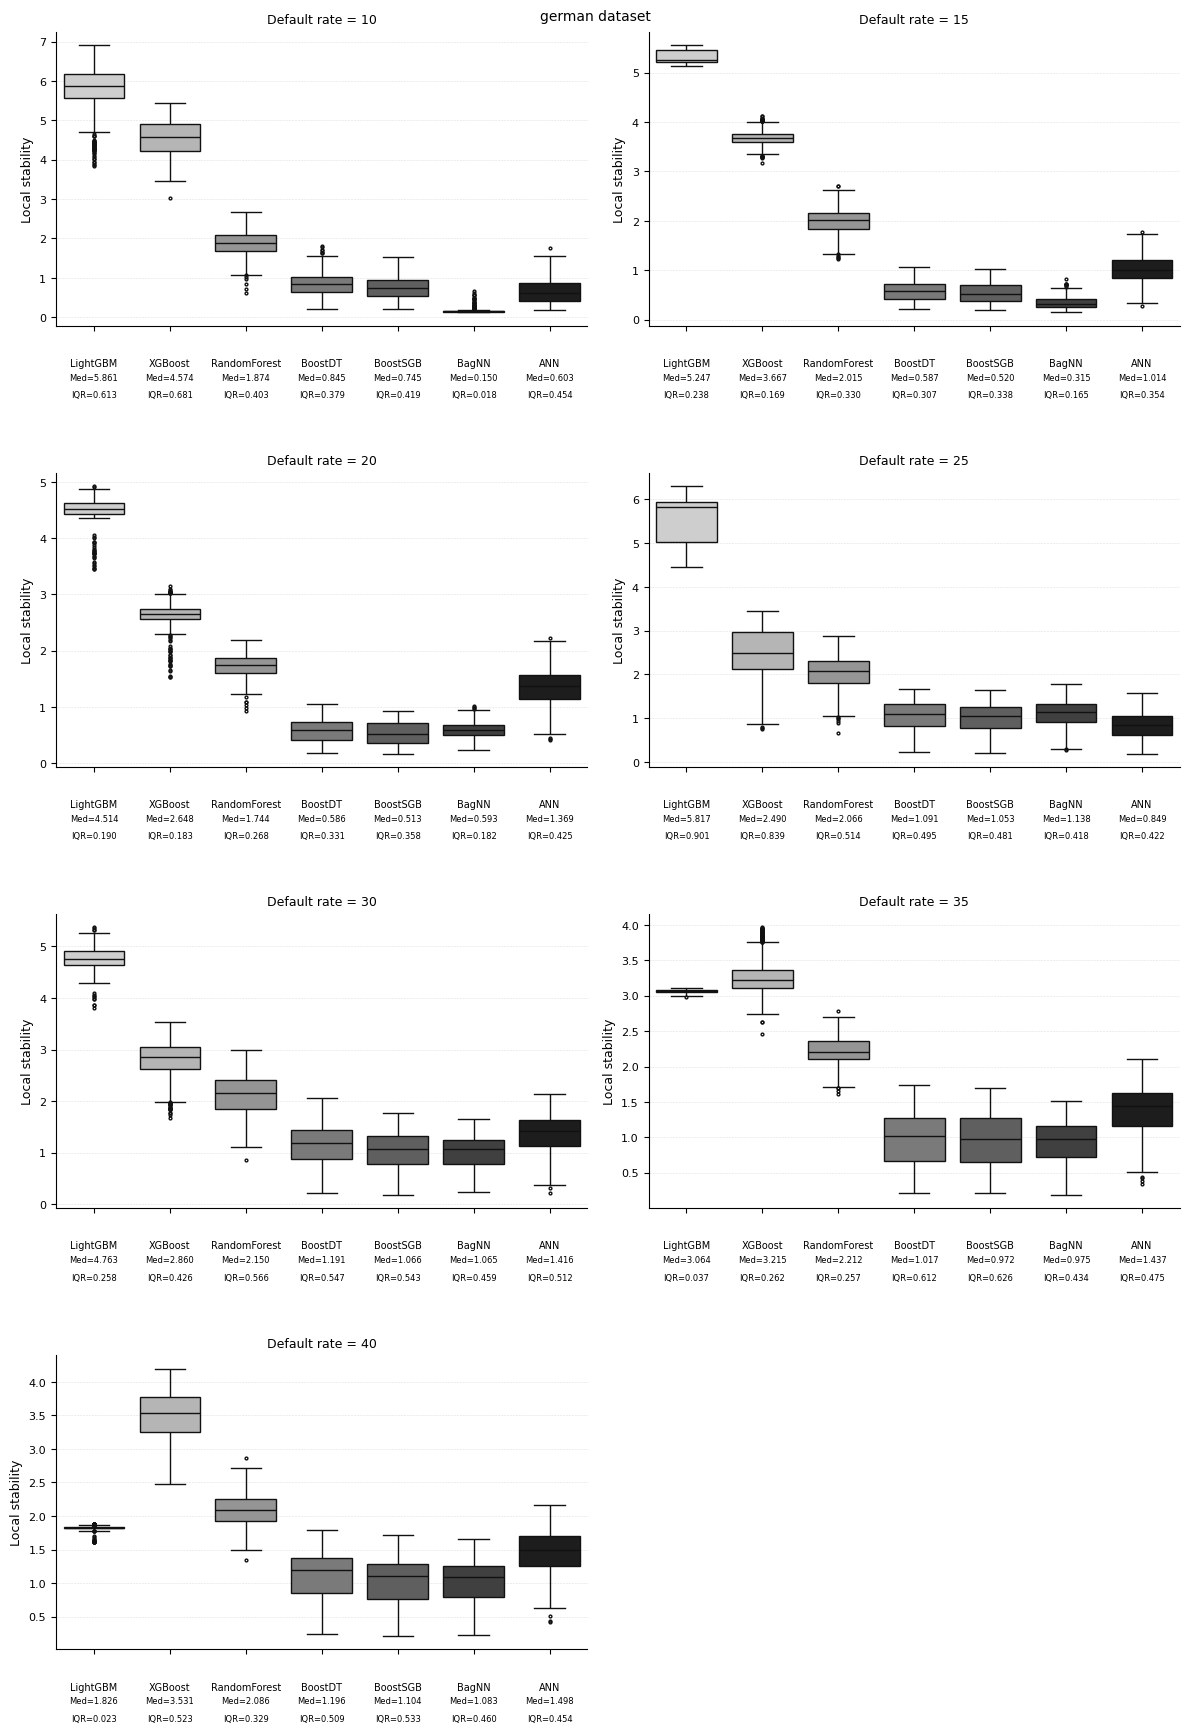

In [11]:
fig, axes = plot_models_by_imbalance(
    df=df_local,
    dataset=dataset,
    models=model_choices,
    imbalance_levels=imbalance_levels,
    metric="rankstab_local_weight",
    ylabel="Local stability",
    xlabel="Model",
    ncols=2,
    suptitle=f"{dataset} dataset",
)

plt.show()

In [12]:
model_choices

['LightGBM', 'XGBoost', 'RandomForest', 'BoostDT', 'BoostSGB', 'BagNN', 'ANN']